<a href="https://colab.research.google.com/github/GabErves/URUT_Analysis/blob/main/URUT_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [10]:
import os
import pandas as pd

file_name = "/content/URUT_userlytics_data.csv"

# Check if the file exists at the absolute system path
if os.path.exists(file_name):
    df = pd.read_csv(file_name, encoding="utf-8-sig")
    df.columns = df.columns.str.strip()
    print("File loaded successfully!")
    display(df.head())
else:
    print(f"Error: '{file_name}' not found. Please verify the exact path.")

File loaded successfully!


,PARTICIPANT-NAME,QUOTA-NAME,GENDER,COUNTRY,AGE,DEVICE TYPE,DEVICE MODEL,OS VERSION,SCREEN RESOLUTION,APPROVED DATE,...,"A1 TIME ON You are solo traveling around the Iberian Peninsula, and are looking for a weekend getaway to Lisbon in October. You are familiar with art history and you've heard really great things about the food scene in Lisbon from your friends. You’re planning to arrive Friday and depart Sunday, and you do not have a set budget.","A1 TIME IN SEC You are solo traveling around the Iberian Peninsula, and are looking for a weekend getaway to Lisbon in October. You are familiar with art history and you've heard really great things about the food scene in Lisbon from your friends. You’re planning to arrive Friday and depart Sunday, and you do not have a set budget.","A2 TIME ON Using the TripAdvisor website, find a place to stay in Lisbon.","A2 TIME IN SEC Using the TripAdvisor website, find a place to stay in Lisbon.","A3 TIME ON Using the TripAdvisor website, find a well-reviewed place to eat in Lisbon.","A3 TIME IN SEC Using the TripAdvisor website, find a well-reviewed place to eat in Lisbon.","A4 TIME ON Using the TripAdvisor website, find a day trip or excursion in Lisbon.","A4 TIME IN SEC Using the TripAdvisor website, find a day trip or excursion in Lisbon.","A5 TIME ON On the TripAdvisor website, figure out how to save and refer to all your ideas for places to stay, dine, and explore.","A5 TIME IN SEC On the TripAdvisor website, figure out how to save and refer to all your ideas for places to stay, dine, and explore."
0,Brenden O.,TripAdvisor,Male,US Hawaii,28,Desktop,NaN,Windows,1536 x 864,2026-10-10 04:30:06,...,00:42,42,05:51,351,02:13,133,06:15,375,00:54,54
1,Jeremy B.,TripAdvisor,Male,US Kentucky,48,Desktop,NaN,Windows,1280 x 720,2026-10-10 12:51:43,...,00:28,28,02:33,153,01:28,88,01:29,89,01:19,79
2,John B.,TripAdvisor,Male,US Arkansas,39,Desktop,NaN,Windows,1536 x 864,2026-10-10 18:36:31,...,00:31,31,02:24,144,01:01,61,01:35,95,00:57,57
3,Kristen T.,TripAdvisor,Female,US Illinois,37,Desktop,NaN,Windows,1366 x 768,2026-10-10 12:56:35,...,00:22,22,01:00,60,00:41,41,00:52,52,00:49,49
4,Mike S.,TripAdvisor,Male,US Washington,55,Desktop,NaN,Windows,1920 x 1080,2026-10-10 10:14:57,...,00:26,26,01:01,61,00:24,24,00:33,33,01:50,110


In [17]:
print(df["COUNTRY"].tolist())   # see every raw value
print(df["COUNTRY"].str.count(",").value_counts())  # how many commas per value

['US Hawaii', 'US Kentucky', 'US Arkansas', 'US Illinois', 'US Washington', 'US California', 'US California', 'US California']
COUNTRY
0    8
Name: count, dtype: int64


In [41]:

#split out US state and country into separate lists
# n=1 means split at most once, so "Florida, United States" -> ["Florida", " United States"]
parts = df["COUNTRY"].str.rsplit(" ", n=1, expand=True)
df["COUNTRY_2"] = parts[0].str.strip()
df["STATE_CLEAN"] = parts[1].str.strip()

print(df["COUNTRY_2"].tolist())
print(df["STATE_CLEAN"].tolist())

['US', 'US', 'US', 'US', 'US', 'US', 'US', 'US']
['Hawaii', 'Kentucky', 'Arkansas', 'Illinois', 'Washington', 'California', 'California', 'California']


In [42]:
#convert seconds into mins
print(df["SESSION DURATION"].head())
print(df["SESSION DURATION"].dtype)
# Integer division: how many whole minutes fit into the session duration.
# 989 // 60 = 16 (989 seconds contains 16 full minutes)
mins = df["SESSION DURATION"] // 60
# Remainder: the seconds left over after removing the whole minutes.
# 989 % 60 = 29 (989 - 16*60 = 29)
secs = df["SESSION DURATION"] % 60
# Build the text value in mm:ss format.
# 1. mins.astype(str)    -> converts the numbers to text: "16"
# 2. .str.zfill(2)       -> pads to 2 characters with leading zeros: "16" stays "16", "7" becomes "07"
# 3. + ":" +              -> joins the parts with a colon
# 4. secs.astype(str)    -> converts the seconds to text: "29"
# 5. .str.zfill(2)       -> pads the seconds too: "5" becomes "05"
# Result for row 0: "16:29"
df["SESSION_MINS"] = mins.astype(str).str.zfill(2) + ":" + secs.astype(str).str.zfill(2)
# print
print(df[["SESSION DURATION", "SESSION_MINS"]].head())

0    989
1    435
2    391
3    225
4    253
Name: SESSION DURATION, dtype: int64
int64
   SESSION DURATION SESSION_MINS
0               989        16:29
1               435        07:15
2               391        06:31
3               225        03:45
4               253        04:13


In [20]:
import re

task_names = {
    "A1": "SCOPE",
    "A2": "STAY",
    "A3": "DINE",
    "A4": "EXCURSION",
    "A5": "SAVE_IDEAS",
}

# Matches only timing headers, e.g. "A2 TIME IN SEC ..." or "A2 TIME ON ..."
timing_pattern = re.compile(r"^(A\d) TIME (ON|IN SEC) ")

def shorten(col):
    m = timing_pattern.match(col)
    if not m:
        return col                      # screeners and other columns stay as they are
    code, kind = m.groups()
    name = task_names[code]
    return f"{name}_TIME_ON" if kind == "ON" else f"{name}_SEC"

df = df.rename(columns=shorten)
print(df.columns.tolist())

['PARTICIPANT-NAME', 'QUOTA-NAME', 'GENDER', 'COUNTRY', 'AGE', 'DEVICE TYPE', 'DEVICE MODEL', 'OS VERSION', 'SCREEN RESOLUTION', 'APPROVED DATE', 'SESSION DURATION', 'A1 SCREENER What is your age range?', 'A2 SCREENER How comfortable are you with reading and speaking in English?', 'A3 SCREENER Are you able to use a desktop or laptop computer to complete this study and have access to the Google Chrome browser?', 'SCOPE_TIME_ON', 'SCOPE_SEC', 'STAY_TIME_ON', 'STAY_SEC', 'DINE_TIME_ON', 'DINE_SEC', 'EXCURSION_TIME_ON', 'EXCURSION_SEC', 'SAVE_IDEAS_TIME_ON', 'SAVE_IDEAS_SEC', 'COUNTRY_2', 'STATE_CLEAN', 'SESSION_MINS']


In [21]:
tasks = ["STAY", "DINE", "EXCURSION", "SAVE_IDEAS"]   # skip ORIENT for task totals

for t in tasks:
    col_data = df[f"{t}_SEC"]

    # If there are duplicate columns with the same name, col_data is a DataFrame
    if isinstance(col_data, pd.DataFrame):
        # Loop through each column, try to make it numeric, and pick the one that has the most numbers (fewest NaNs)
        best_series = None
        min_nans = float('inf')
        for col_idx in range(col_data.shape[1]):
            converted = pd.to_numeric(col_data.iloc[:, col_idx], errors='coerce')
            nans_count = converted.isna().sum()
            if nans_count < min_nans:
                min_nans = nans_count
                best_series = converted
        numeric_sec = best_series
    else:
        numeric_sec = pd.to_numeric(col_data, errors='coerce')

    df[f"{t}_MIN"] = (numeric_sec / 60).round(2)

df["TOTAL_TASK_MIN"] = df[[f"{t}_MIN" for t in tasks]].sum(axis=1)
print(df[[f"{t}_MIN" for t in tasks] + ["TOTAL_TASK_MIN"]].head())

   STAY_MIN  DINE_MIN  EXCURSION_MIN  SAVE_IDEAS_MIN  TOTAL_TASK_MIN
0      5.85      2.22           6.25            0.90           15.22
1      2.55      1.47           1.48            1.32            6.82
2      2.40      1.02           1.58            0.95            5.95
3      1.00      0.68           0.87            0.82            3.37
4      1.02      0.40           0.55            1.83            3.80


In [22]:
import os

# Recursively search for any CSV files in the workspace to see where it was uploaded
found_files = []
for root, dirs, files in os.walk('.'):
    for file in files:
        if file.lower().endswith('.csv') or 'urut' in file.lower():
            found_files.append(os.path.join(root, file))

if found_files:
    print("Found matching files in your workspace:")
    for f in found_files:
        print(f" - {f}")
else:
    print("No CSV or 'URUT' files found. Please make sure the upload has completed in the left panel (look for the circle progress bar to finish).")

Found matching files in your workspace:
 - ./URUT_userlytics_data.csv
 - ./sample_data/mnist_train_small.csv
 - ./sample_data/california_housing_train.csv
 - ./sample_data/california_housing_test.csv
 - ./sample_data/mnist_test.csv


In [23]:
task_min_cols = ["STAY_MIN", "DINE_MIN", "EXCURSION_MIN", "SAVE_IDEAS_MIN"]

# 1. Average task time per participant: sum of the 4 tasks / 4
df["AVG_TASK_MIN"] = df[task_min_cols].mean(axis=1).round(2)

# 2. Average orientation (scenario reading) time, in minutes, across all 8 participants
df["SCOPE_MIN"] = df["SCOPE_SEC"] / 60
avg_orient_min = df["SCOPE_MIN"].mean()

# 3. Average time per task across all 8 participants: sum of 8 / 8
task_avgs = df[task_min_cols].mean()

# 4. Average of the per-participant averages (overall average task time)
overall_avg_task_min = df["AVG_TASK_MIN"].mean()

print(df[["PARTICIPANT-NAME"] + task_min_cols + ["AVG_TASK_MIN"]])
print("Avg orientation time (min):", round(avg_orient_min, 2))
print(task_avgs.round(2))
print("Overall avg task time (min):", round(overall_avg_task_min, 2))

  PARTICIPANT-NAME  STAY_MIN  DINE_MIN  EXCURSION_MIN  SAVE_IDEAS_MIN  \
0       Brenden O.      5.85      2.22           6.25            0.90   
1        Jeremy B.      2.55      1.47           1.48            1.32   
2          John B.      2.40      1.02           1.58            0.95   
3       Kristen T.      1.00      0.68           0.87            0.82   
4          Mike S.      1.02      0.40           0.55            1.83   
5       Richard C.      5.27      2.50           2.28            3.98   
6       Stephon T.      3.22      1.87           2.13            1.60   
7         Tanya T.      3.88      1.85           1.53            1.48   

   AVG_TASK_MIN  
0          3.80  
1          1.70  
2          1.49  
3          0.84  
4          0.95  
5          3.51  
6          2.20  
7          2.18  
Avg orientation time (min): 0.51
STAY_MIN          3.15
DINE_MIN          1.50
EXCURSION_MIN     2.08
SAVE_IDEAS_MIN    1.61
dtype: float64
Overall avg task time (min): 2.08


In [24]:
screener_names = {
    "A1 SCREENER": "AGE_RANGE",       # "What is your age range?"
    "A2 SCREENER": "ENGLISH_COMFORT", # "How comfortable are you with reading and speaking in English?"
    "A3 SCREENER": "DESKTOP_ACCESS",  # "Are you able to use a desktop or laptop...?"
}

def shorten_screener(col):
    for prefix, name in screener_names.items():
        if col.startswith(prefix):
            return name
    return col  # any other column stays as it is

df = df.rename(columns=shorten_screener)
print(df.columns.tolist())

['PARTICIPANT-NAME', 'QUOTA-NAME', 'GENDER', 'COUNTRY', 'AGE', 'DEVICE TYPE', 'DEVICE MODEL', 'OS VERSION', 'SCREEN RESOLUTION', 'APPROVED DATE', 'SESSION DURATION', 'AGE_RANGE', 'ENGLISH_COMFORT', 'DESKTOP_ACCESS', 'SCOPE_TIME_ON', 'SCOPE_SEC', 'STAY_TIME_ON', 'STAY_SEC', 'DINE_TIME_ON', 'DINE_SEC', 'EXCURSION_TIME_ON', 'EXCURSION_SEC', 'SAVE_IDEAS_TIME_ON', 'SAVE_IDEAS_SEC', 'COUNTRY_2', 'STATE_CLEAN', 'SESSION_MINS', 'STAY_MIN', 'DINE_MIN', 'EXCURSION_MIN', 'SAVE_IDEAS_MIN', 'TOTAL_TASK_MIN', 'AVG_TASK_MIN', 'SCOPE_MIN']


In [25]:
pd.set_option("display.max_columns", None)   # show all columns instead of truncating
pd.set_option("display.width", None)         # don't wrap onto multiple lines
print(df)                                    # the full table

  PARTICIPANT-NAME   QUOTA-NAME  GENDER        COUNTRY  AGE DEVICE TYPE  \
0       Brenden O.  TripAdvisor    Male      US Hawaii   28     Desktop   
1        Jeremy B.  TripAdvisor    Male    US Kentucky   48     Desktop   
2          John B.  TripAdvisor    Male    US Arkansas   39     Desktop   
3       Kristen T.  TripAdvisor  Female    US Illinois   37     Desktop   
4          Mike S.  TripAdvisor    Male  US Washington   55     Desktop   
5       Richard C.  TripAdvisor    Male  US California   28     Desktop   
6       Stephon T.  TripAdvisor    Male  US California   58     Desktop   
7         Tanya T.  TripAdvisor  Female  US California   45     Desktop   

   DEVICE MODEL OS VERSION SCREEN RESOLUTION        APPROVED DATE  \
0           NaN    Windows        1536 x 864  2026-10-10 04:30:06   
1           NaN    Windows        1280 x 720  2026-10-10 12:51:43   
2           NaN    Windows        1536 x 864  2026-10-10 18:36:31   
3           NaN    Windows        1366 x 768  20

In [26]:
import matplotlib.pyplot as plt

tasks = ["STAY", "DINE", "EXCURSION", "SAVE_IDEAS"]
task_cols = [f"{t}_MIN" for t in tasks]

print(df[task_cols].describe().round(2))   # quick check before plotting

       STAY_MIN  DINE_MIN  EXCURSION_MIN  SAVE_IDEAS_MIN
count      8.00      8.00           8.00            8.00
mean       3.15      1.50           2.08            1.61
std        1.79      0.75           1.78            1.02
min        1.00      0.40           0.55            0.82
25%        2.05      0.94           1.33            0.94
50%        2.88      1.66           1.56            1.40
75%        4.23      1.96           2.17            1.66
max        5.85      2.50           6.25            3.98


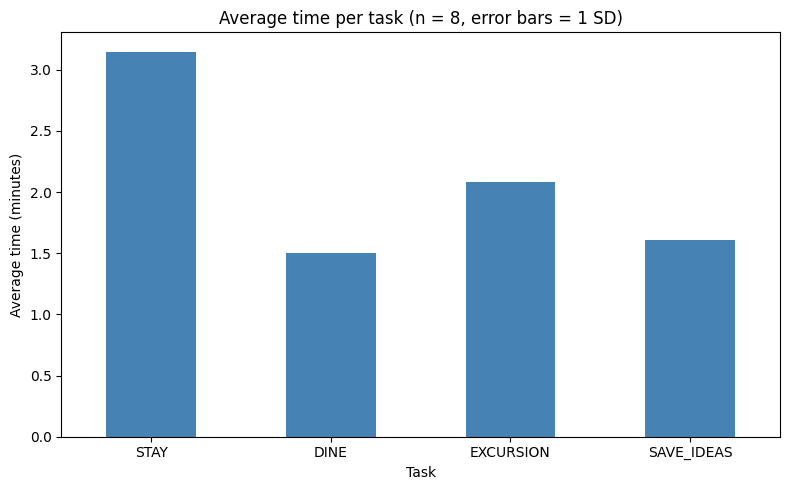

In [27]:
means = df[task_cols].mean()
stds = df[task_cols].std()
means.index = tasks                        # use short labels on the x-axis

ax = means.plot(kind="bar", yerr=stds, capsize=4, color="steelblue", figsize=(8, 5))
ax.set_xlabel("Task")
ax.set_ylabel("Average time (minutes)")
ax.set_title("Average time per task (n = 8, error bars = 1 SD)")
ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

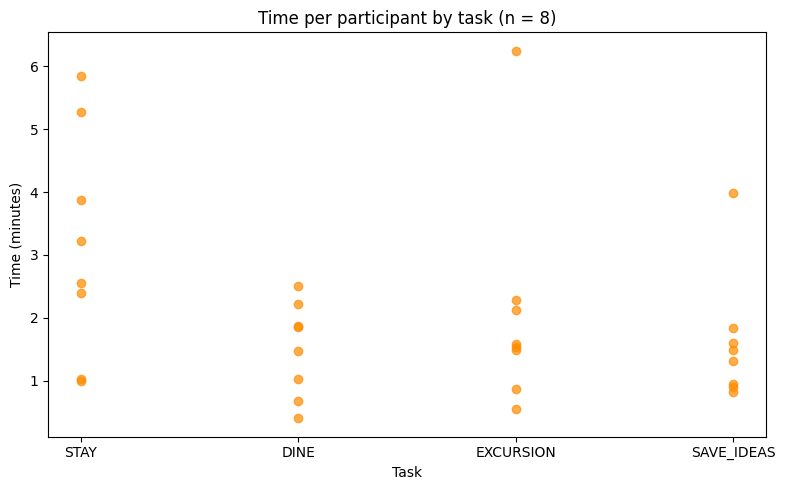

In [28]:
fig, ax = plt.subplots(figsize=(8, 5))

for i, col in enumerate(task_cols):
    ax.scatter([i] * len(df), df[col], alpha=0.7, color="darkorange")

ax.set_xticks(range(len(tasks)))
ax.set_xticklabels(tasks)
ax.set_xlabel("Task")
ax.set_ylabel("Time (minutes)")
ax.set_title("Time per participant by task (n = 8)")
plt.tight_layout()
plt.show()

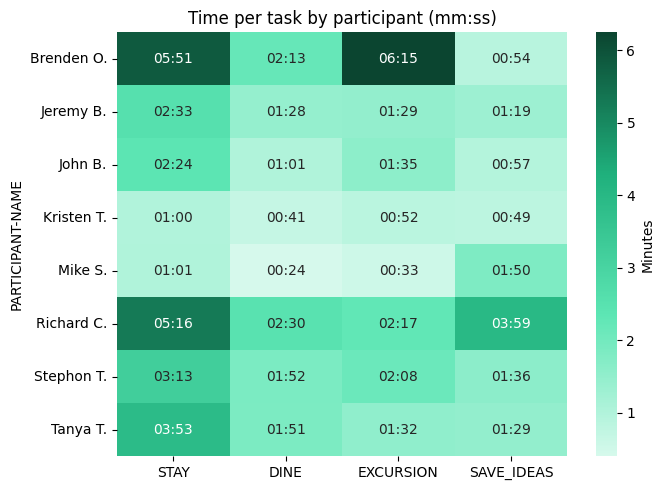

In [29]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap


tasks = ["STAY", "DINE", "EXCURSION", "SAVE_IDEAS"]
task_cols = [f"{t}_MIN" for t in tasks]

# Numeric grid: controls the colors
grid = df.set_index("PARTICIPANT-NAME")[task_cols]
grid.columns = tasks

# Convert decimal minutes to mm:ss text
def to_mmss(minutes):
    total_sec = int(round(minutes * 60))   # 16.48 min -> 989 sec
    mins, secs = divmod(total_sec, 60)     # 989 -> (16, 29)
    return f"{mins:02d}:{secs:02d}"

labels = grid.map(to_mmss)                 # use grid.applymap on pandas older than 2.1

my_cmap = LinearSegmentedColormap.from_list(
    "custom",
    ["#d6f9ec", "#5de6b4", "#1FB07C", "#0b4530"],   # low -> high
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    grid,                                  # numbers drive the colors
    annot=labels.to_numpy(),               # text drives the labels
    fmt="",                                # required when annot is text
    cmap=my_cmap,
    cbar_kws={"label": "Minutes"},         # seaborn uses cbar_kws, not cbar_label
)

plt.title("Time per task by participant (mm:ss)")
plt.tight_layout()
plt.savefig("Time_per_task.png", dpi=200, bbox_inches="tight")
plt.show()

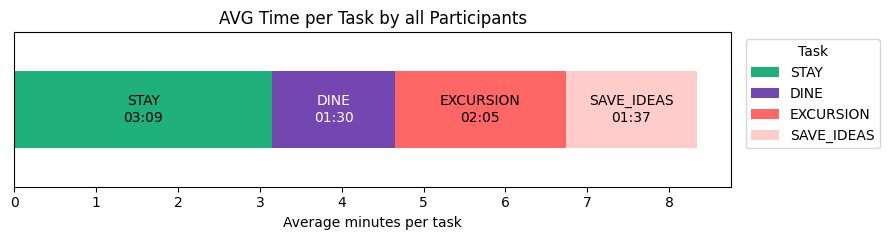

In [38]:
share = df[task_cols].mean()

share.index = tasks
task_colors = {
    "STAY": "#1FB07C",
    "DINE": "#7446AF",
    "EXCURSION": "#FF6666",
    "SAVE_IDEAS": "#FFCCCC",
}
colors = [task_colors[t] for t in tasks]
ax = share.to_frame().T.plot(kind="barh", stacked=True, color=colors, figsize=(9, 2.5))

# Label each segment with its average time, in mm:ss
# Each container is one task's segment in the stacked bar
for container, task in zip(ax.containers, tasks):
    value = share[task]
    label = to_mmss(value)
    # Dark segments get white text, light segments get black text
    text_color = "white" if task_colors[task] in ("#7446AF") else "black"
    ax.bar_label(
        container,
        labels=[f"{task}\n{label}"],   # task name and time on two lines
        label_type="center",
        color=text_color,
        fontsize=10,
    )
ax.set_xlabel("Average minutes per task")
ax.set_yticks([])                        # one bar, so no row label is needed
ax.legend(title="Task", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.title("AVG Time per Task by all Participants")
plt.tight_layout()
plt.savefig("Avg_time_per_task.png", dpi=200, bbox_inches="tight")
plt.show()

<Axes: >

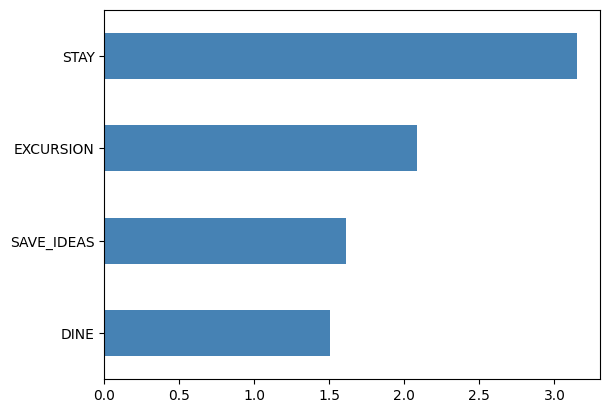

In [31]:
ranked = means.sort_values(ascending=True)
ranked.plot(kind="barh", color="steelblue")

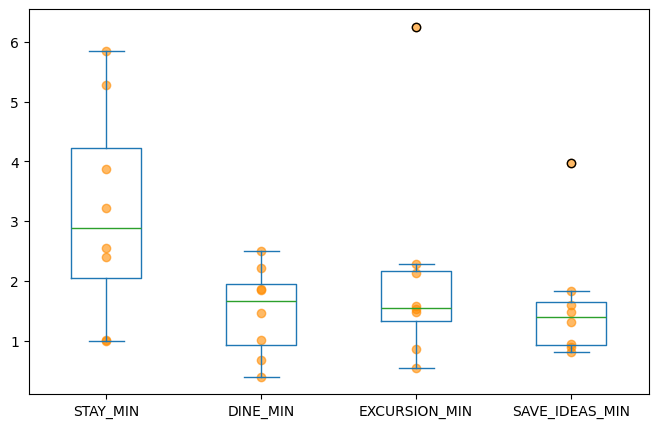

In [ ]:
ax = df[task_cols].plot(kind="box", figsize=(8, 5))
for i, col in enumerate(task_cols, start=1):
    ax.scatter([i] * len(df), df[col], alpha=0.6, color="darkorange")

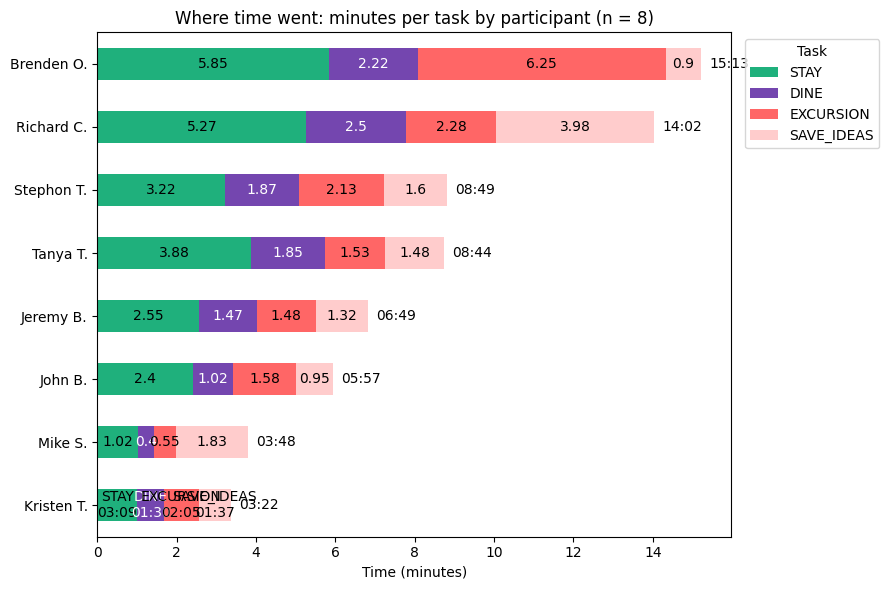

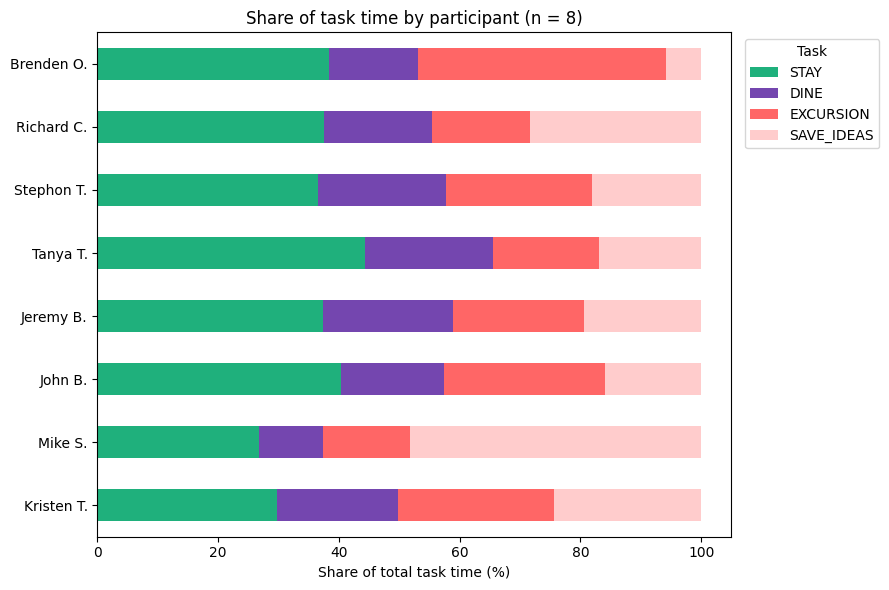

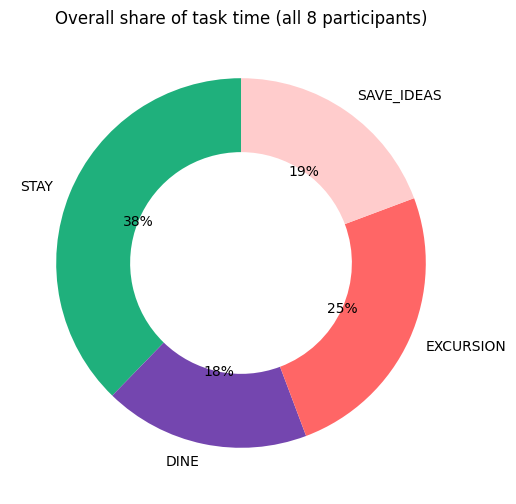

In [40]:
import numpy as np
import matplotlib.pyplot as plt

tasks = ["STAY", "DINE", "EXCURSION", "SAVE_IDEAS"]
task_cols = [f"{t}_MIN" for t in tasks]

plot_df = df.set_index("PARTICIPANT-NAME")[task_cols].copy()
plot_df.columns = tasks

# Sort participants by total task time so the longest bars sit at the top
plot_df = plot_df.loc[plot_df.sum(axis=1).sort_values().index]

# Pull four colors from the custom heatmap palette
colors = my_cmap(np.linspace(0.25, 0.95, len(tasks)))

task_colors = {
    "STAY": "#1FB07C",
    "DINE": "#7446AF",
    "EXCURSION": "#FF6666",
    "SAVE_IDEAS": "#FFCCCC",
}
colors = [task_colors[t] for t in tasks]   # same order as the columns

# Chart 1: minutes per task, stacked by participant, with total labels

ax = plot_df.plot(kind="barh", stacked=True, color=colors, figsize=(9, 6))
for i, total in enumerate(plot_df.sum(axis=1)):
    ax.text(total + 0.2, i, to_mmss(total), va="center")   # uses the to_mmss function from before
# Label each segment with its average time, in mm:ss
# Each container is one task's segment in the stacked bar
for container, task in zip(ax.containers, tasks):
    value = share[task]
    label = to_mmss(value)
    # Dark segments get white text, light segments get black text
    text_color = "white" if task_colors[task] in ("#7446AF") else "black"
    ax.bar_label(
        container,
        labels=[f"{task}\n{label}"],   # task name and time on two lines
        label_type="center",
        color=text_color,
        fontsize=10,
    )
ax.set_xlabel("Time (minutes)")
ax.set_ylabel("")
ax.set_title("Where time went: minutes per task by participant (n = 8)")
ax.legend(title="Task", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("where_time_went.png", dpi=200, bbox_inches="tight")
plt.show()

# Chart 2: share of each participant's total time, as percentages
shares = plot_df.div(plot_df.sum(axis=1), axis=0) * 100
ax = shares.plot(kind="barh", stacked=True, color=colors, figsize=(9, 6))
ax.set_xlabel("Share of total task time (%)")
ax.set_ylabel("")
ax.set_title("Share of task time by participant (n = 8)")
ax.legend(title="Task", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.savefig("share_time_task.png", dpi=200, bbox_inches="tight")
plt.show()

# Chart 3: overall share across all participants (donut)
overall = plot_df.sum()
plt.figure(figsize=(6, 6))
plt.pie(overall, labels=overall.index, colors=colors, autopct="%1.0f%%",
        startangle=90, wedgeprops={"width": 0.4})
plt.title("Overall share of task time (all 8 participants)")
plt.savefig("Percent_task_share.png", dpi=200, bbox_inches="tight")
plt.show()

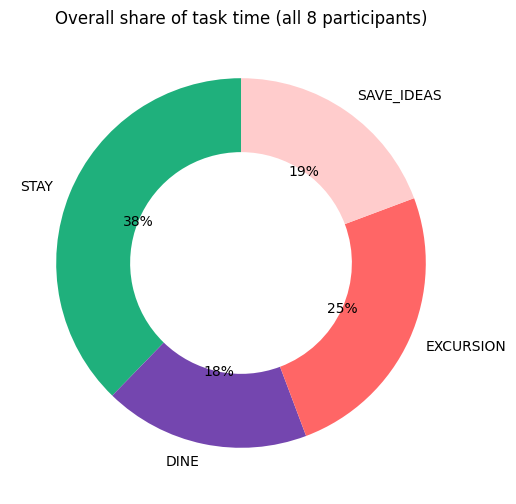

In [47]:
# Chart 3: overall share across all participants (donut)
overall = plot_df.sum()
text_color = "white" if task_colors[task] in ("#7446AF") else "black"
plt.figure(figsize=(6, 6))
plt.pie(overall, labels=overall.index, colors=colors, autopct="%1.0f%%",
        startangle=90, wedgeprops={"width": 0.4})
plt.title("Overall share of task time (all 8 participants)")
plt.savefig("Percent_task_share.png", dpi=200, bbox_inches="tight")
plt.show()

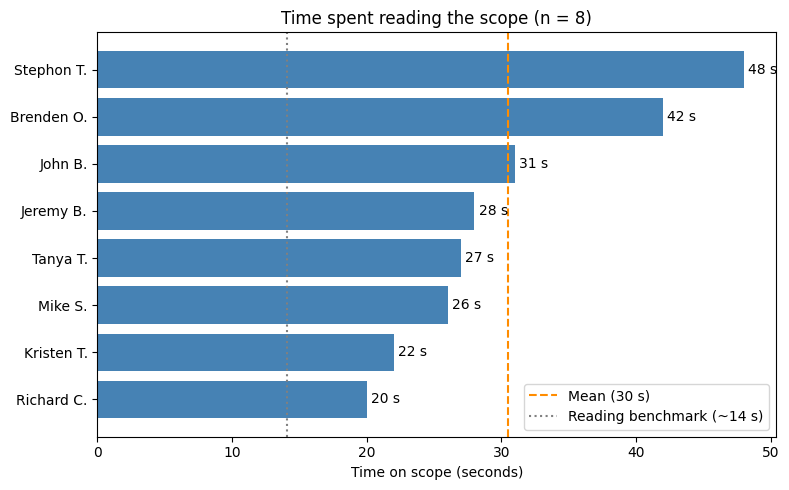

In [ ]:
import matplotlib.pyplot as plt

scope = df[["PARTICIPANT-NAME", "SCOPE_SEC"]].copy()
scope["SCOPE_SEC"] = pd.to_numeric(scope["SCOPE_SEC"], errors="coerce")
scope = scope.sort_values("SCOPE_SEC")

mean_s = scope["SCOPE_SEC"].mean()      # about 30.5 s
median_s = scope["SCOPE_SEC"].median()  # 27.5 s

# Reference point: the scope is 56 words, and average adult silent reading is about 238 words per minute
benchmark_s = 56 / 238 * 60             # about 14 s

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.barh(scope["PARTICIPANT-NAME"], scope["SCOPE_SEC"], color="steelblue")
ax.bar_label(bars, fmt="%d s", padding=3)

ax.axvline(mean_s, color="darkorange", linestyle="--", label=f"Mean ({mean_s:.0f} s)")
ax.axvline(benchmark_s, color="gray", linestyle=":", label=f"Reading benchmark (~{benchmark_s:.0f} s)")

ax.set_xlabel("Time on scope (seconds)")
ax.set_title("Time spent reading the scope (n = 8)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("scope_reading_time.png", dpi=200, bbox_inches="tight")
plt.show()

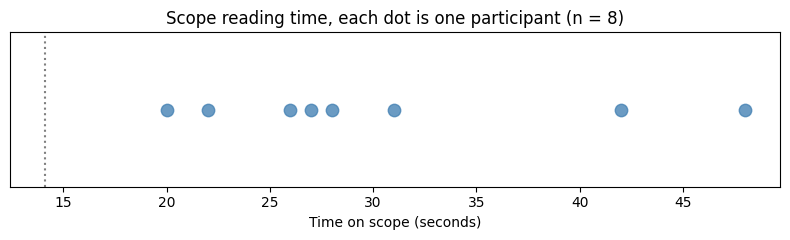

In [ ]:
fig, ax = plt.subplots(figsize=(8, 2.5))
ax.scatter(scope["SCOPE_SEC"], [0] * len(scope), s=80, color="steelblue", alpha=0.8)
ax.axvline(benchmark_s, color="gray", linestyle=":")
ax.set_yticks([])
ax.set_xlabel("Time on scope (seconds)")
ax.set_title("Scope reading time, each dot is one participant (n = 8)")
plt.tight_layout()
plt.show()

In [ ]:
# Fill in the three participants from your notes, using the exact PARTICIPANT-NAME values
flagged = ["Brenden O.", "Richard C.", "John B."]
df["SCOPE_REVISIT"] = df["PARTICIPANT-NAME"].isin(flagged)

print(df.groupby("SCOPE_REVISIT")["STAY_MIN"].agg(["mean", "median", "count"]).round(2))

               mean  median  count
SCOPE_REVISIT                     
False          2.33    2.55      5
True           4.51    5.27      3


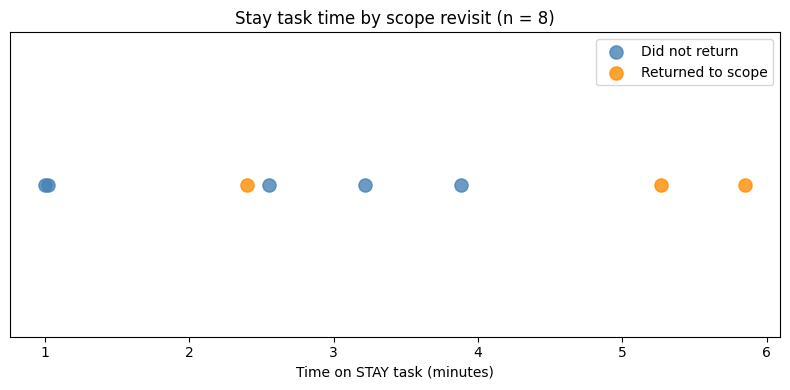

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
for flag, group in df.groupby("SCOPE_REVISIT"):
    ax.scatter(group["STAY_MIN"], [0] * len(group),
               s=90, alpha=0.8,
               color="darkorange" if flag else "steelblue",
               label="Returned to scope" if flag else "Did not return")
ax.set_yticks([])
ax.set_xlabel("Time on STAY task (minutes)")
ax.set_title("Stay task time by scope revisit (n = 8)")
ax.legend()
plt.tight_layout()
plt.savefig("stay_by_scope_revisit.png", dpi=200, bbox_inches="tight")
plt.show()